# England and Wales house prices, 2024–2026

What did homes actually sell for, and how do those prices differ by place, property type, and tenure?

The source is HM Land Registry Price Paid Data: residential sales in England and Wales lodged for registration. This notebook uses the yearly files for 2024, 2025, and 2026. The 2026 file was published on 28 October 2026 and runs through September. Scotland and Northern Ireland are outside this register.

The charts are written to `reports/figures/` and reused in the README.


In [1]:
%matplotlib inline

from pathlib import Path
import json
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

def show(fig):
    display(fig)
    plt.close(fig)

ROOT = Path.cwd().resolve()
if not (ROOT / "src").exists() and (ROOT.parent / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

from house_prices.plotting import (
    format_gbp,
    plot_local_authorities,
    plot_monthly_trend,
    plot_new_build,
    plot_price_distribution,
    plot_property_type,
    plot_region_type_heatmap,
    plot_regional_medians,
    plot_tenure,
    plot_volume_index,
)
from house_prices.prepare import load_or_build
from house_prices.schema import EDA_SUMMARY_PATH, FIGURE_DIR, REPORT_DIR

FIGURE_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_rows", 20)
pd.set_option("display.float_format", lambda value: f"{value:,.1f}")


## What is counted

A row is one completed sale. The cleaning rules, implemented in `house_prices.clean`, keep standard residential sales only:

- Price Paid category A (a single home sold for value). Category B mixes repossessions, some buy-to-lets, sales to companies, and non-standard property.
- The four dwelling types Land Registry records: detached, semi-detached, terraced, and flat. In this extract every "other" property is already in category B.
- Prices from £10,000 to £5,000,000. That removes a handful of nominal amounts and the extreme right tail.
- County is mapped to an English region or to Wales. The mapping covers every county name in these three files.

August and September 2026 are marked provisional. Land Registry says the latest two months are incomplete because registration lags completion, and this file was published on 28 October 2026. Medians below use the complete months unless a chart says otherwise.


In [2]:
sales = load_or_build()
complete = sales.loc[~sales["provisional"]].copy()
stats = json.loads((REPORT_DIR / "prepare_stats.json").read_text())

headline = pd.DataFrame(
    {
        "All rows in the yearly files": [stats["rows_read"]],
        "Category B and other exclusions": [stats["rows_read"] - stats["rows_kept"]],
        "Sales in the analysis table": [len(sales)],
        "Of which provisional (Aug–Sep 2026)": [int(sales["provisional"].sum())],
        "Complete months": [len(complete)],
    },
    index=["Sales"],
).T
headline["Sales"] = headline["Sales"].map(lambda value: f"{int(value):,}")
display(headline)

median_price = float(complete["price"].median())
mean_price = float(complete["price"].mean())
display(Markdown(
    f"From **{complete['transfer_date'].min():%B %Y}** to **{complete['transfer_date'].max():%B %Y}** "
    f"the median standard sale was **{format_gbp(median_price)}** "
    f"(mean {format_gbp(mean_price)}). "
    f"The mean sits above the median because the right tail is long: "
    f"the 95th percentile is {format_gbp(float(complete['price'].quantile(0.95)))}."
))


,Sales
All rows in the yearly files,"2,382,455"
Category B and other exclusions,"404,102"
Sales in the analysis table,"1,978,353"
Of which provisional (Aug–Sep 2026),"60,350"
Complete months,"1,918,003"


From **January 2024** to **July 2026** the median standard sale was **£295k** (mean £364k). The mean sits above the median because the right tail is long: the 95th percentile is £830k.

## Prices over time

The monthly median is the right summary: a few expensive sales move the mean, and March 2025 is a reminder that the mix of homes can move the median too.


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


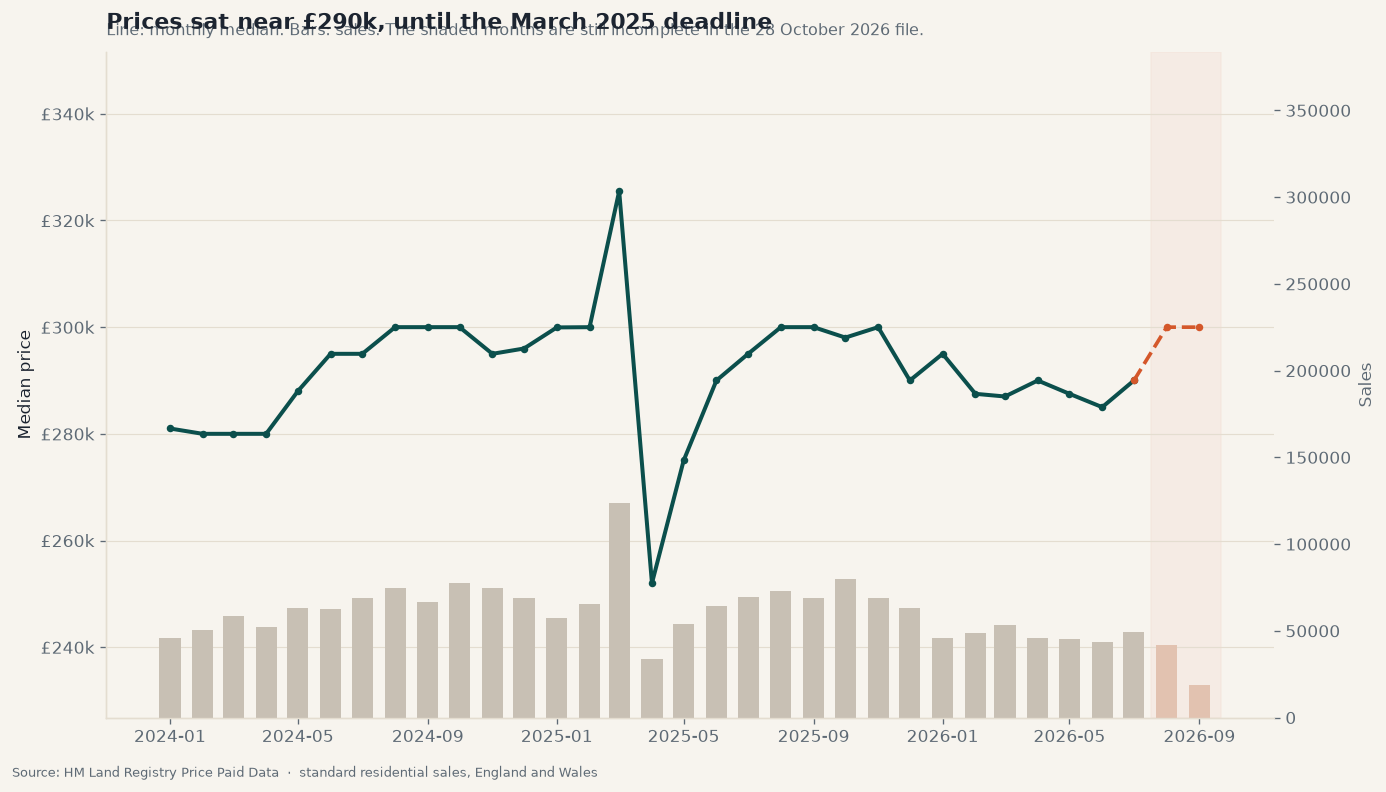

In [3]:
monthly = (
    sales.groupby(sales["transfer_date"].dt.to_period("M"))
    .agg(
        median_price=("price", "median"),
        sales=("price", "size"),
        provisional=("provisional", "max"),
    )
    .reset_index(names="month")
)
monthly["month"] = monthly["month"].dt.to_timestamp()
show(plot_monthly_trend(monthly, FIGURE_DIR / "01_monthly_median_and_volume.png"))


In [4]:
march = monthly.loc[monthly["month"].eq(pd.Timestamp("2025-03-01"))].iloc[0]
april = monthly.loc[monthly["month"].eq(pd.Timestamp("2025-04-01"))].iloc[0]
jan24 = monthly.iloc[0]
last_complete = monthly.loc[~monthly["provisional"]].iloc[-1]
display(Markdown(
    f"The median opened at **{format_gbp(jan24.median_price)}** in {jan24.month:%B %Y} and was "
    f"**{format_gbp(last_complete.median_price)}** in {last_complete.month:%B %Y}. "
    f"In between it sat close to £290–300k, with one break: **{format_gbp(march.median_price)}** "
    f"in March 2025 ({int(march.sales):,} sales) and **{format_gbp(april.median_price)}** "
    f"in April ({int(april.sales):,} sales)."
))


The median opened at **£281k** in January 2024 and was **£290k** in July 2026. In between it sat close to £290–300k, with one break: **£326k** in March 2025 (123,716 sales) and **£252k** in April (33,982 sales).

## The March 2025 rush was English, not British

On 1 April 2025 the residential stamp duty nil-rate band in England and Northern Ireland reverted from £250,000 to £125,000. Wales charges Land Transaction Tax, which did not change on that date. If the volume spike is a completion deadline, it should show up in England and not in Wales.


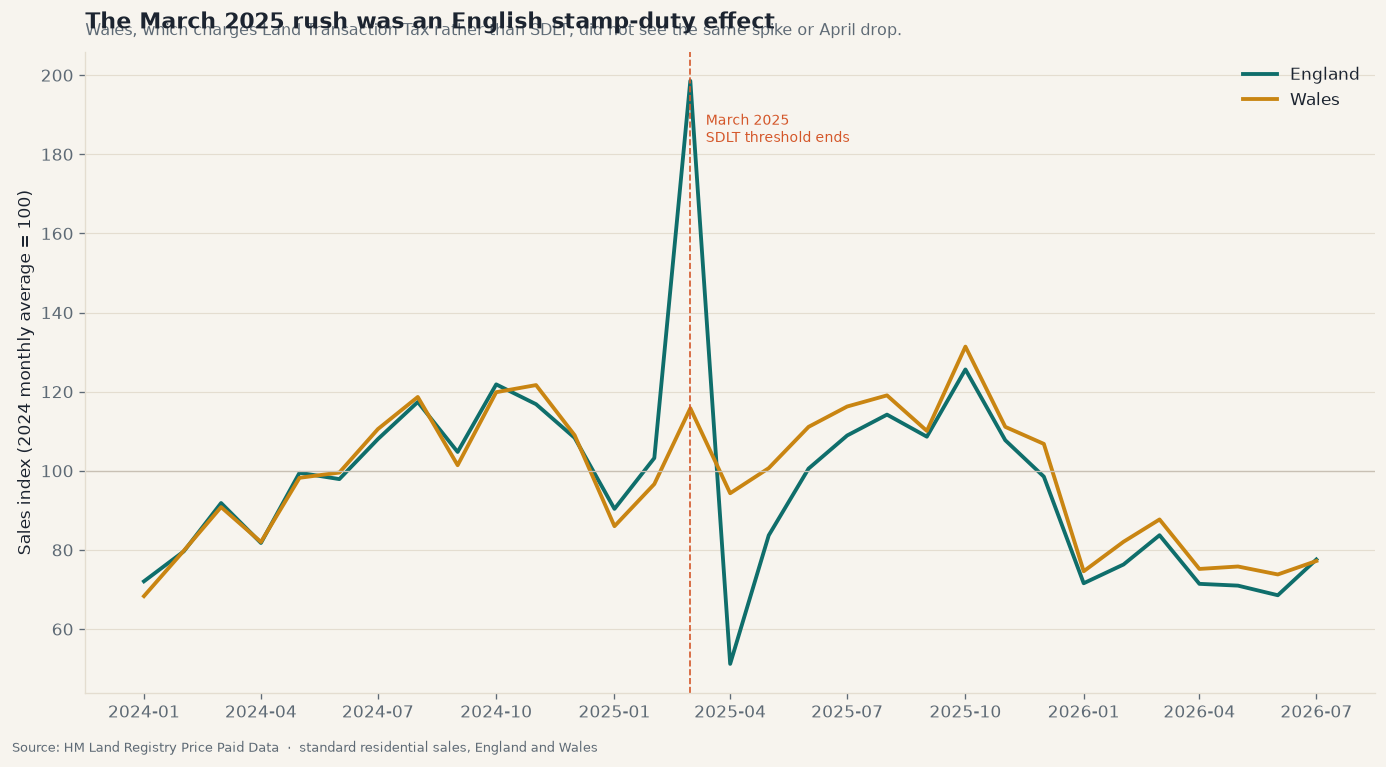

Indexed to each nation's own 2024 monthly average, England reached **199** in March 2025 (119,975 sales) and fell to **51** in April (30,935). Wales was **116** in March (3,741) and **94** in April (3,047). The price mix moved with the volume: England's median went from the February level up in March and down sharply in April, while the Welsh median did not.

In [5]:
volume = (
    complete.groupby([complete["transfer_date"].dt.to_period("M"), "nation"])
    .size()
    .rename("sales")
    .reset_index()
)
volume["month"] = volume["transfer_date"].dt.to_timestamp()
baseline = (
    volume.loc[volume["month"].dt.year.eq(2024)]
    .groupby("nation")["sales"]
    .mean()
)
volume["index"] = volume["sales"] / volume["nation"].map(baseline) * 100
show(plot_volume_index(volume, FIGURE_DIR / "02_england_wales_volume_index.png"))

def index_at(nation, when):
    row = volume.loc[volume["nation"].eq(nation) & volume["month"].eq(pd.Timestamp(when))].iloc[0]
    return float(row["index"]), int(row["sales"])

eng_mar, eng_mar_n = index_at("England", "2025-03-01")
eng_apr, eng_apr_n = index_at("England", "2025-04-01")
wal_mar, wal_mar_n = index_at("Wales", "2025-03-01")
wal_apr, wal_apr_n = index_at("Wales", "2025-04-01")
display(Markdown(
    f"Indexed to each nation's own 2024 monthly average, England reached **{eng_mar:.0f}** in March 2025 "
    f"({eng_mar_n:,} sales) and fell to **{eng_apr:.0f}** in April ({eng_apr_n:,}). "
    f"Wales was **{wal_mar:.0f}** in March ({wal_mar_n:,}) and **{wal_apr:.0f}** in April ({wal_apr_n:,}). "
    "The price mix moved with the volume: England's median went from the February level up in March and down sharply in April, while the Welsh median did not."
))


## Regions

County names in the file are ceremonial or unitary counties. They are mapped to the nine English regions and to Wales. London here is Greater London, not the wider commuting region.


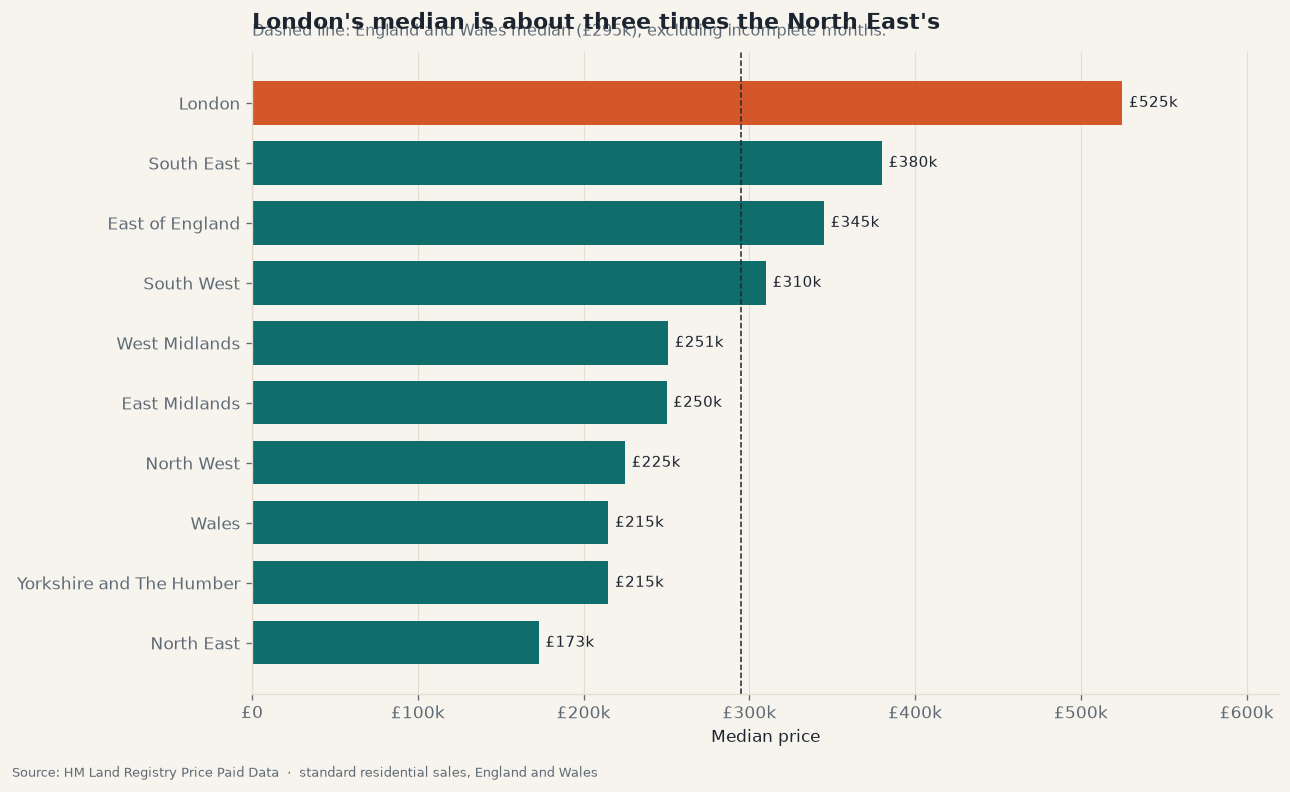

**London** has the highest median, **£525k** (204,036 sales). **North East** has the lowest, **£173k**. London is 3.0 times the North East median. The England and Wales median is £295k.

,region,median_price,sales
2,London,"525,000.0",204036
5,South East,"380,011.0",318698
1,East of England,"345,000.0",218511
6,South West,"310,000.0",211919
8,West Midlands,"251,000.0",176415
0,East Midlands,"250,000.0",170744
4,North West,"225,000.0",245538
7,Wales,"215,000.0",98379
9,Yorkshire and The Humber,"214,995.0",182947
3,North East,"173,000.0",90816


In [6]:
regions = (
    complete.groupby("region")
    .agg(median_price=("price", "median"), sales=("price", "size"))
    .reset_index()
)
show(plot_regional_medians(regions, median_price, FIGURE_DIR / "03_regional_median_price.png"))
top = regions.sort_values("median_price", ascending=False).iloc[0]
bottom = regions.sort_values("median_price", ascending=True).iloc[0]
display(Markdown(
    f"**{top.region}** has the highest median, **{format_gbp(top.median_price)}** "
    f"({int(top.sales):,} sales). **{bottom.region}** has the lowest, **{format_gbp(bottom.median_price)}**. "
    f"London is {top.median_price / bottom.median_price:.1f} times the {bottom.region} median. "
    f"The England and Wales median is {format_gbp(median_price)}."
))
regions.sort_values("median_price", ascending=False)


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


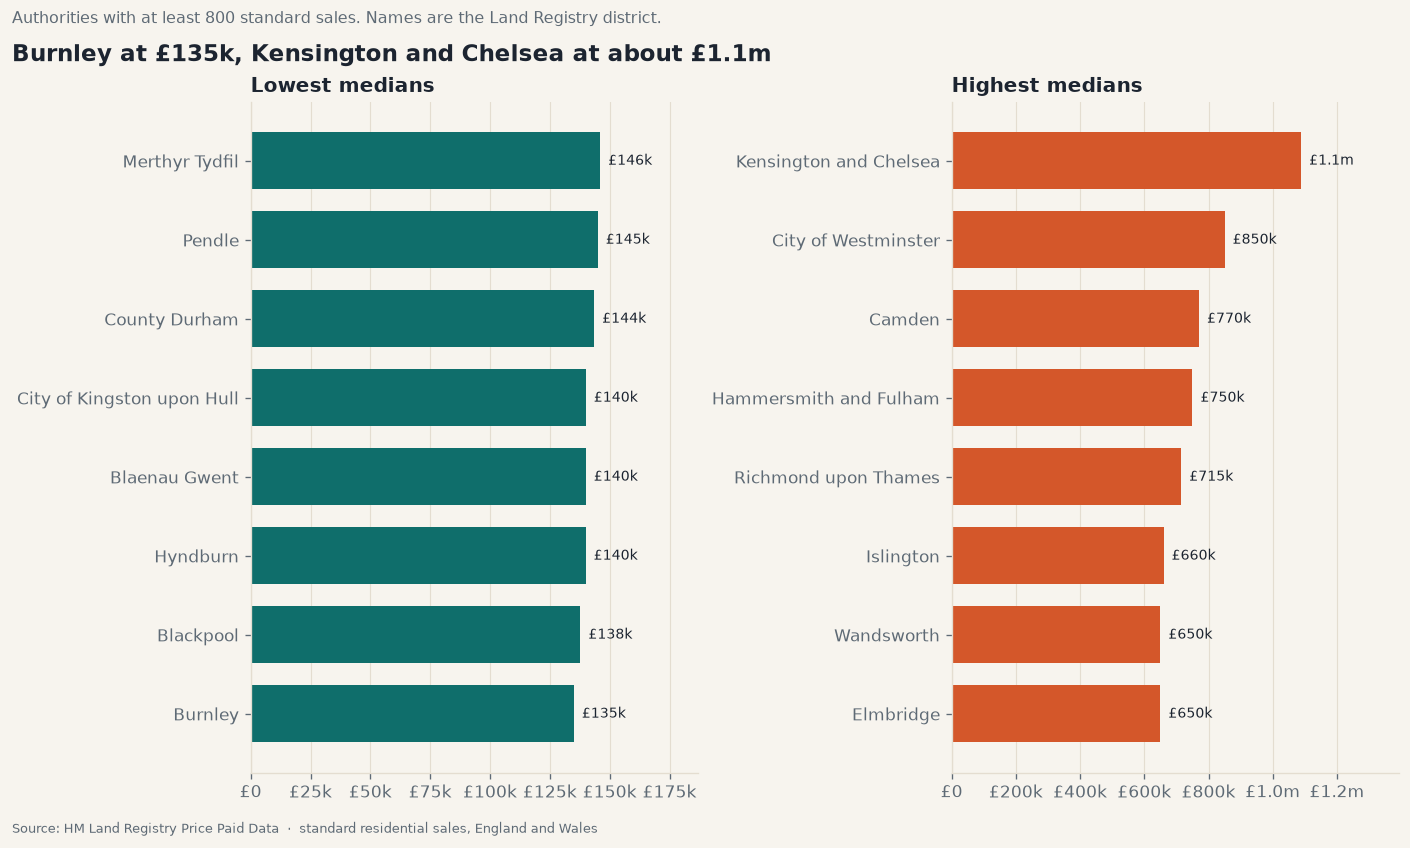

Among local authorities with at least 800 sales, **Burnley** (£135k) and **Kensington and Chelsea** (£1.1m) are the ends of the range: about 8 times apart. Several of the lowest medians are Lancashire authorities; the highest are London boroughs.

In [7]:
authorities = (
    complete.groupby("local_authority")
    .agg(median_price=("price", "median"), sales=("price", "size"))
    .reset_index()
)
authorities = authorities.loc[authorities["sales"].ge(800)]
lowest = authorities.nsmallest(8, "median_price")
highest = authorities.nlargest(8, "median_price")
show(plot_local_authorities(highest, lowest, FIGURE_DIR / "04_local_authority_medians.png"))
cheap = lowest.sort_values("median_price").iloc[0]
dear = highest.sort_values("median_price").iloc[-1]
display(Markdown(
    f"Among local authorities with at least 800 sales, **{cheap.local_authority}** "
    f"({format_gbp(cheap.median_price)}) and **{dear.local_authority}** "
    f"({format_gbp(dear.median_price)}) are the ends of the range: "
    f"about {dear.median_price / cheap.median_price:.0f} times apart. "
    "Several of the lowest medians are Lancashire authorities; the highest are London boroughs."
))


## Property type, new build, and tenure

Land Registry does not publish floor area, bedrooms, or condition. Property type, the new-build flag, and tenure are the physical attributes in the file. Medians by type are not adjusted for where the homes are, so part of each gap is geography. The heatmap later in the notebook holds region fixed.


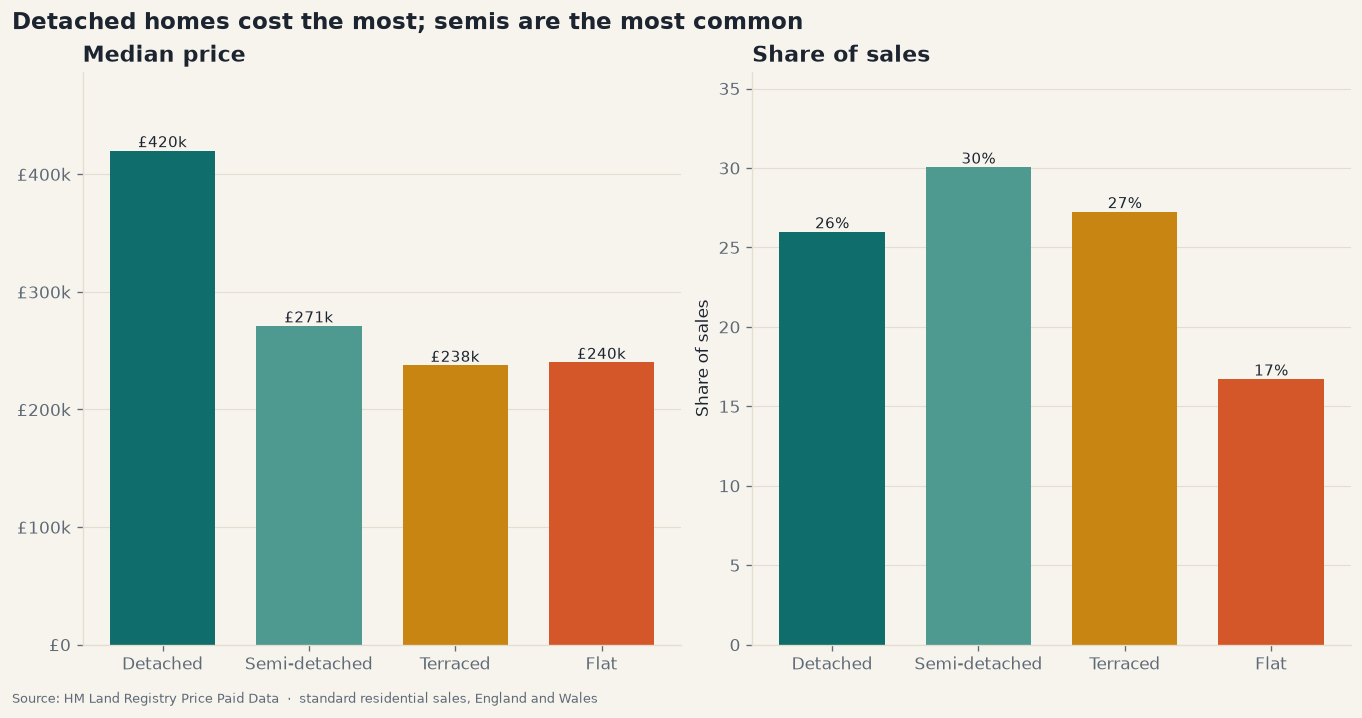

,property_type,median_price,sales,share
0,Detached,"419,995.0",498341,0.3
2,Semi-detached,"271,000.0",576386,0.3
1,Flat,"240,000.0",320607,0.2
3,Terraced,"237,500.0",522669,0.3


In [8]:
type_stats = (
    complete.groupby("property_type")
    .agg(median_price=("price", "median"), sales=("price", "size"))
    .reset_index()
)
type_stats["share"] = type_stats["sales"] / type_stats["sales"].sum()
show(plot_property_type(type_stats, FIGURE_DIR / "05_property_type.png"))
type_stats.sort_values("median_price", ascending=False)


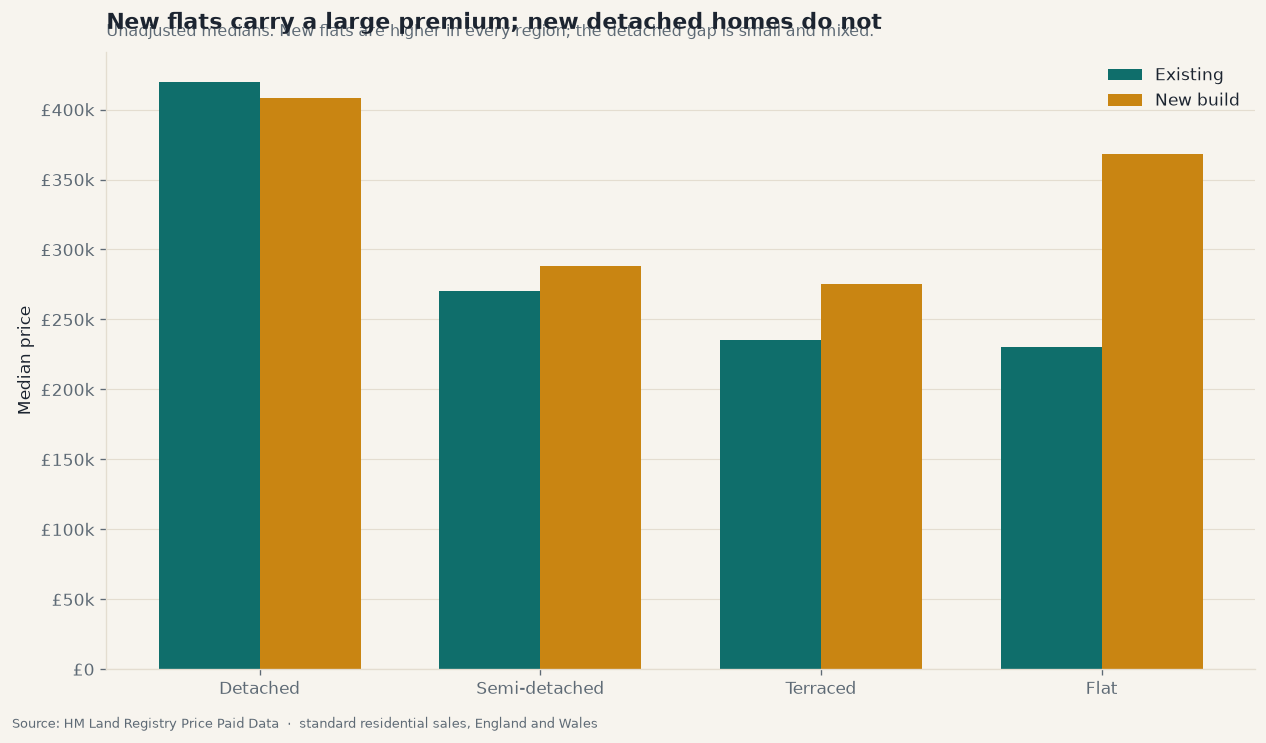

New builds are **6.7%** of complete-month sales. A new flat's median is **£369k**, against **£230k** for an existing flat (+60%). That premium is present in **10 of 10** regions, so it is not only a London mix effect. New detached homes (**£408k**) sit slightly below existing detached homes (**£420k**). Within regions the detached gap is small and changes sign, which is what you would expect if new estates are not in the same places as the existing detached stock.

In [9]:
new_stats = (
    complete.groupby(["property_type", "new_build"])
    .agg(median_price=("price", "median"), sales=("price", "size"))
    .reset_index()
)
show(plot_new_build(new_stats, FIGURE_DIR / "06_new_build_premium.png"))

flat = new_stats.loc[new_stats["property_type"].eq("Flat")].set_index("new_build")["median_price"]
detached = new_stats.loc[new_stats["property_type"].eq("Detached")].set_index("new_build")["median_price"]
new_share = float((complete["new_build"] == "New build").mean())
by_region = (
    complete.loc[complete["property_type"].eq("Flat")]
    .groupby(["region", "new_build"])["price"]
    .median()
    .unstack()
)
regions_with_premium = int((by_region["New build"] > by_region["Existing"]).sum())
display(Markdown(
    f"New builds are **{new_share:.1%}** of complete-month sales. "
    f"A new flat's median is **{format_gbp(flat['New build'])}**, against **{format_gbp(flat['Existing'])}** for an existing flat "
    f"({flat['New build'] / flat['Existing'] - 1:+.0%}). That premium is present in **{regions_with_premium} of {len(by_region)}** regions, "
    f"so it is not only a London mix effect. "
    f"New detached homes (**{format_gbp(detached['New build'])}**) sit slightly below existing detached homes "
    f"(**{format_gbp(detached['Existing'])}**). Within regions the detached gap is small and changes sign, "
    "which is what you would expect if new estates are not in the same places as the existing detached stock."
))


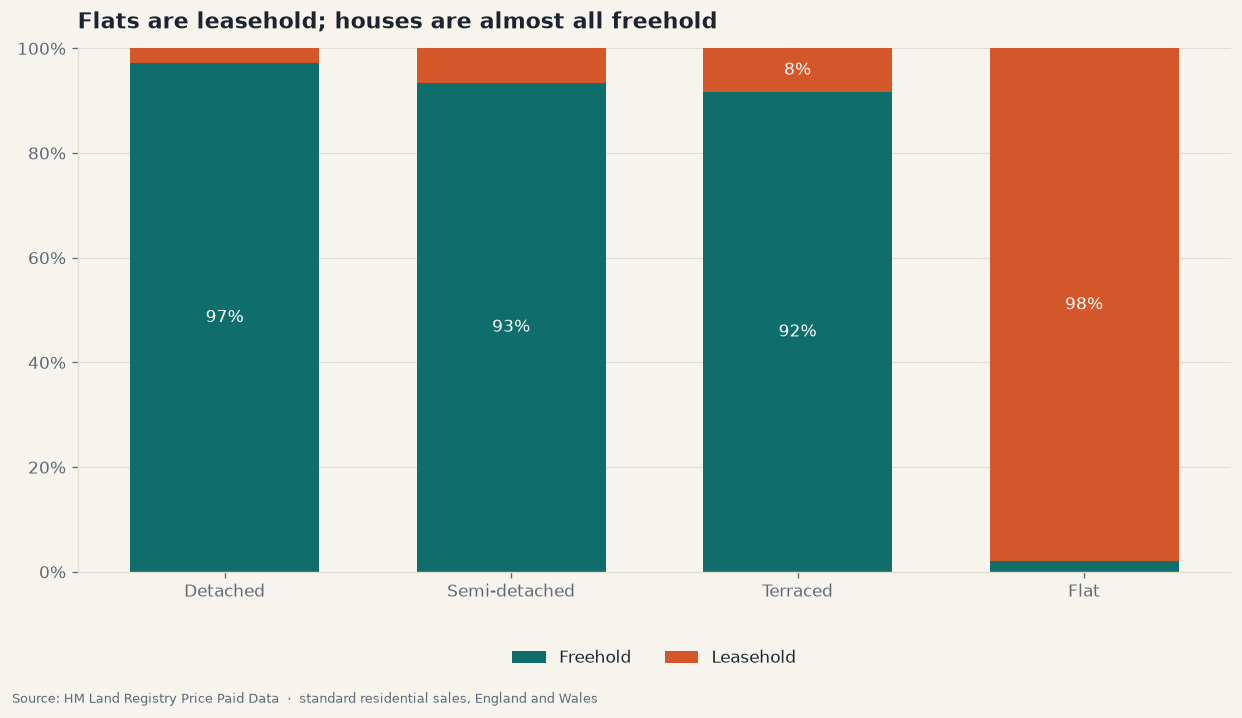

**98%** of flats are leasehold. Freehold shares for houses are detached 97%, semi-detached 93%, terraced 92%. Leasehold houses are the exception, not the product.

In [10]:
tenure = (
    complete.groupby(["property_type", "tenure"])
    .size()
    .rename("sales")
    .reset_index()
)
tenure["share"] = tenure["sales"] / tenure.groupby("property_type")["sales"].transform("sum")
show(plot_tenure(tenure, FIGURE_DIR / "07_tenure_by_type.png"))
flat_lease = float(tenure.loc[tenure["property_type"].eq("Flat") & tenure["tenure"].eq("Leasehold"), "share"].iloc[0])
house = tenure.loc[tenure["property_type"].ne("Flat") & tenure["tenure"].eq("Freehold"), ["property_type", "share"]]
display(Markdown(
    f"**{flat_lease:.0%}** of flats are leasehold. Freehold shares for houses are "
    + ", ".join(f"{row.property_type.lower()} {row.share:.0%}" for row in house.itertuples())
    + ". Leasehold houses are the exception, not the product."
))


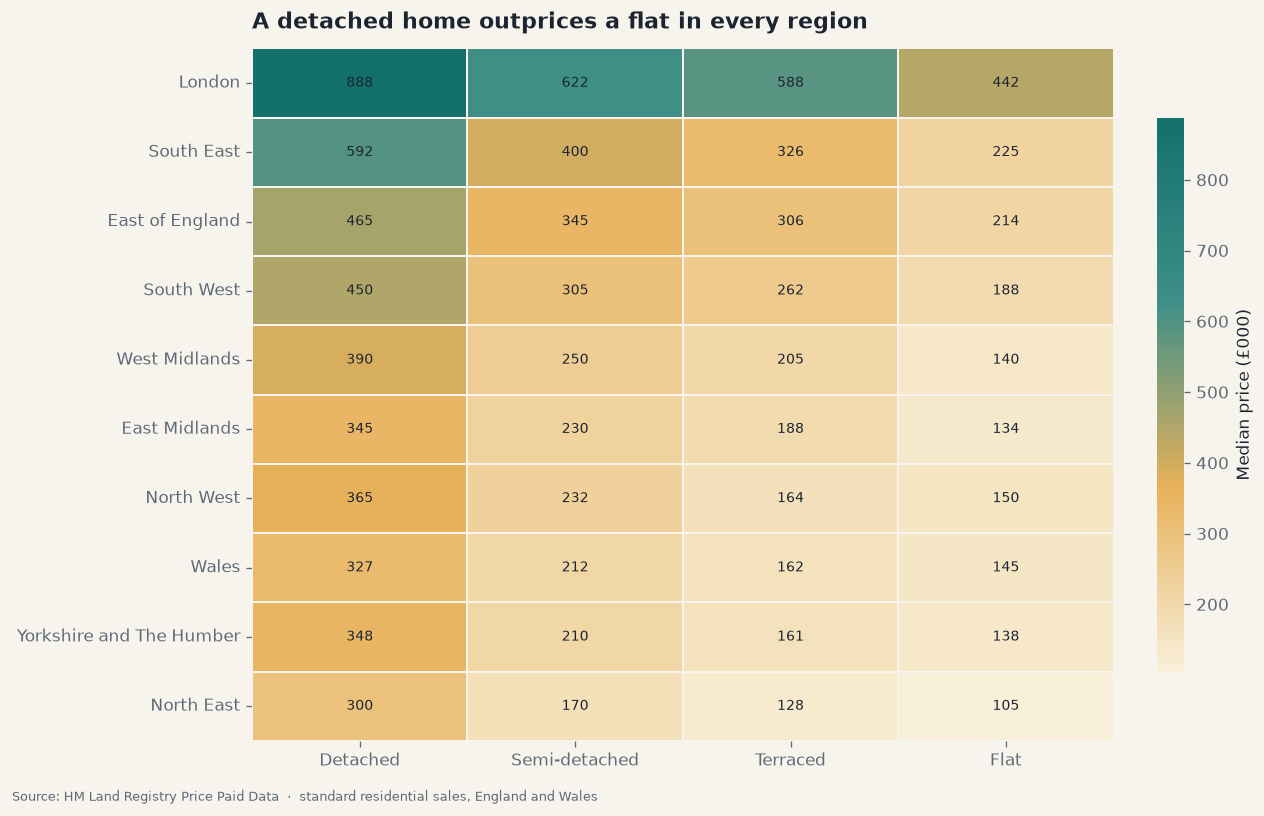

Reading across a row is the type gap in one region. Reading down a column is the regional gap for one type. A detached house in London has a median of **£888k**; a flat in the North East has a median of **£105k**.

In [11]:
heatmap = complete.pivot_table(
    index="region",
    columns="property_type",
    values="price",
    aggfunc="median",
)
order = regions.sort_values("median_price", ascending=False)["region"]
heatmap = heatmap.loc[order]
show(plot_region_type_heatmap(heatmap, FIGURE_DIR / "08_region_type_heatmap.png"))
display(Markdown(
    "Reading across a row is the type gap in one region. Reading down a column is the regional gap for one type. "
    f"A detached house in London has a median of **{format_gbp(heatmap.loc['London', 'Detached'])}**; "
    f"a flat in the North East has a median of **{format_gbp(heatmap.loc['North East', 'Flat'])}**."
))


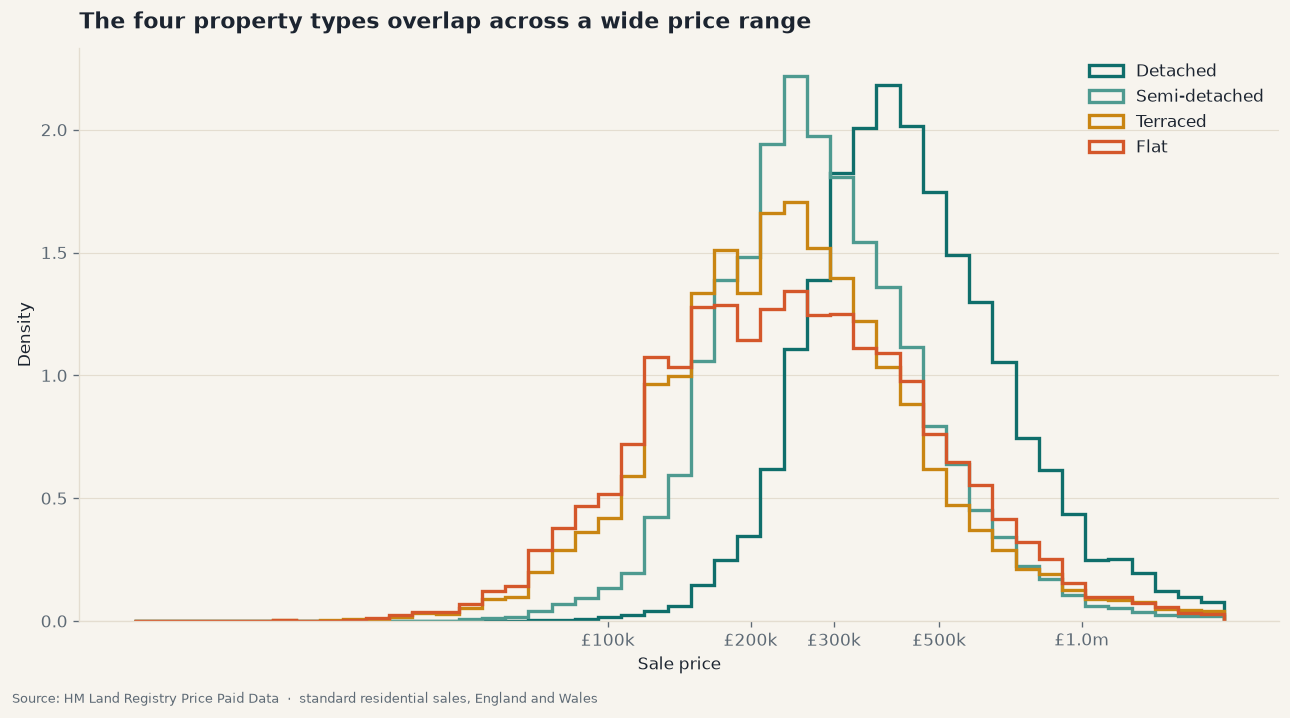

In [12]:
show(plot_price_distribution(complete, FIGURE_DIR / "09_price_distribution.png"))


In [13]:
summary = {
    "n_rows_read": stats["rows_read"],
    "n_excluded": stats["rows_read"] - stats["rows_kept"],
    "n_sales": int(len(sales)),
    "n_provisional": int(sales["provisional"].sum()),
    "n_complete": int(len(complete)),
    "date_min": str(complete["transfer_date"].min().date()),
    "date_max_complete": str(complete["transfer_date"].max().date()),
    "date_max_including_provisional": str(sales["transfer_date"].max().date()),
    "median_price": median_price,
    "mean_price": mean_price,
    "p95_price": float(complete["price"].quantile(0.95)),
    "new_build_share": new_share,
    "flat_leasehold_share": flat_lease,
    "regions": regions.sort_values("median_price", ascending=False).to_dict(orient="records"),
    "property_types": type_stats.to_dict(orient="records"),
    "new_build": new_stats.to_dict(orient="records"),
    "monthly": [
        {
            "month": row.month.strftime("%Y-%m"),
            "median_price": float(row.median_price),
            "sales": int(row.sales),
            "provisional": bool(row.provisional),
        }
        for row in monthly.itertuples()
    ],
    "england_march_2025_index": eng_mar,
    "england_april_2025_index": eng_apr,
    "wales_march_2025_index": wal_mar,
    "wales_april_2025_index": wal_apr,
    "lowest_authority": {"name": cheap.local_authority, "median_price": float(cheap.median_price), "sales": int(cheap.sales)},
    "highest_authority": {"name": dear.local_authority, "median_price": float(dear.median_price), "sales": int(dear.sales)},
}
EDA_SUMMARY_PATH.write_text(json.dumps(summary, indent=2) + "\n", encoding="utf-8")
print(f"Wrote {EDA_SUMMARY_PATH}")


Wrote /workspace/reports/eda_summary.json
